# 芯片测试 3/3：PAT 离群筛选、过杀漏测与测试效率

**目标**：

1. **PAT（Part Average Testing）**：在**已经通过全部规格**的芯片里，找出"合格但可疑"的——
   它们是潜在的可靠性风险，规格线抓不到。
2. **过杀与漏测**（仅模拟数据）：模拟数据带"上帝视角"的真值，可以直接数出测试系统冤枉了多少好芯片、
   放过了多少坏芯片。真实产线没有这个，只能靠复测、可靠性试验、客退间接估计。
3. **测试效率**：测试时间花在哪、哪些测试项看起来冗余、测试顺序能否更省。

**输入**：Notebook 01 的 `chip_parts.csv`、`chip_tests.csv`，Notebook 02 写出的 `chip_summary.json`，
以及 `data/raw/chip/truth.csv`（仅模拟数据）

**输出**：`reports/chip/c06`、`c07` 两张图；补全 `data/processed/chip_summary.json`

与 Python 版（`chiptest/parametric.py`、`evaluation.py`、`efficiency.py`）同一套算法，
由 `tests/test_chip_notebook_parity.py` 对照。

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")

cwd = Path.cwd()
ROOT = next((folder.parent for folder in (cwd, *cwd.parents) if folder.name == "notebooks"), cwd)
CLEAN = ROOT / "data" / "processed" / "chip_parts.csv"
TESTS = ROOT / "data" / "processed" / "chip_tests.csv"
SUMMARY = ROOT / "data" / "processed" / "chip_summary.json"
TRUTH = ROOT / "data" / "raw" / "chip" / "truth.csv"
FIGURES = ROOT / "reports" / "chip"
FIGURES.mkdir(parents=True, exist_ok=True)


def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / name, dpi=150, bbox_inches="tight")

## 1. 载入数据（含仿真真值）

In [2]:
if not (CLEAN.exists() and TESTS.exists() and SUMMARY.exists()):
    raise FileNotFoundError(
        "先依次运行 Notebook 01、02，生成清洗数据与 chip_summary.json 的前半部分"
    )

df = pd.read_csv(CLEAN, parse_dates=["test_time", "date"], dtype={"wafer_id": str, "part_id": str})
tests = pd.read_csv(TESTS)
first = df[df["is_first_pass"]]

DIE_KEY = ["lot_id", "wafer_id", "x", "y"]
truth = pd.read_csv(TRUTH, dtype={"wafer_id": str}) if TRUTH.exists() else None
first_t = (
    first.merge(truth, on=DIE_KEY, how="left", validate="one_to_one")
    if truth is not None
    else first
)
print(
    f"{len(first):,} 颗首测芯片；仿真真值：{'有' if truth is not None else '无（按真实产线处理）'}"
)
if truth is not None:
    print("truth.csv 的列：", ", ".join(c for c in truth.columns if c not in DIE_KEY))

71,907 颗首测芯片；仿真真值：有
truth.csv 的列： defect_type, is_weak, intrinsic_pass


## 2. PAT：在"合格"芯片里找可疑的

过了规格线不等于可靠：漏电偏大的芯片可能有微小缺陷，早期失效风险更高。
但漏电本来就和速度正相关（快的芯片漏电大是**正常**的），所以不能只设一条静态阈值。

- **静态 PAT（朴素基线）**：每个测试项在 (lot, 测试机) 内算稳健 z，取各项绝对值的最大值，超过 6σ 标出。
  漏电的分布本身就很宽（随速度、工艺角指数变化），"速度一般但漏电偏大"的芯片，
  在这个宽分布里并不显得极端。
- **残差法 PAT（邻近残差思路）**：用速度（`SCAN_FMAX`）和工作电流（`IDD_ACTIVE`）预测"预期漏电"，
  看实际漏电偏离预期多少个稳健 σ。每个 (lot, 测试机) 单独拟合一条稳健回归：
  先 OLS，再反复剔除偏离超过 3σ 的点后重拟合，让离群点不污染基线。

PAT 只对**已通过全部规格、数据完整**的芯片做：目标是找出"合格但可疑"的。

In [3]:
LOG_TESTS = {"IDD_STANDBY"}


def robust_sigma(x):
    x = np.asarray(x, dtype=float)
    x = x[~np.isnan(x)]
    return float(1.4826 * np.median(np.abs(x - np.median(x)))) if len(x) else np.nan


def scale_values(values, test):
    return np.log(values.clip(lower=1e-12)) if test in LOG_TESTS else values


def residual_zscores(frame, target, predictors, by, trim=3.0):
    z = pd.Series(np.nan, index=frame.index)
    for _, g in frame.groupby(by):
        g = g.dropna(subset=[target, *predictors])
        if len(g) < 50:
            continue
        y = np.log(g[target].to_numpy())
        X = np.column_stack([np.ones(len(g)), g[predictors].to_numpy()])
        keep = np.ones(len(g), dtype=bool)
        for _ in range(4):
            beta, *_ = np.linalg.lstsq(X[keep], y[keep], rcond=None)
            resid = y - X @ beta
            med, sigma = np.median(resid[keep]), robust_sigma(resid[keep])
            keep = np.abs(resid - med) < trim * sigma
        z.loc[g.index] = (resid - med) / sigma
    return z


def static_zscores(frame, names, by):
    worst = pd.Series(0.0, index=frame.index)
    for _, g in frame.groupby(by):
        for t in names:
            v = scale_values(g[t], t)
            sigma = robust_sigma(v)
            if sigma and not np.isnan(sigma):
                worst.loc[g.index] = np.maximum(
                    worst.loc[g.index], ((v - v.median()) / sigma).abs().fillna(0)
                )
    return worst


def passing_complete(first, names):
    return first[first["tester_pass"] & first["final_ok"] & first[names].notna().all(axis=1)]

In [4]:
PAT_TARGET = "IDD_STANDBY"
PAT_PREDICTORS = ["SCAN_FMAX", "IDD_ACTIVE"]
PAT_K = (3.5, 4.0)
PAT_STATIC_TESTS = ["IDD_STANDBY", "IDD_ACTIVE", "SCAN_FMAX", "VMIN"]
BY = ["lot_id", "station"]

ok = passing_complete(first_t, [PAT_TARGET, *PAT_PREDICTORS, *PAT_STATIC_TESTS])
z_resid = residual_zscores(ok, PAT_TARGET, PAT_PREDICTORS, BY)
z_static = static_zscores(ok, PAT_STATIC_TESTS, BY)
pat_frame = ok[["lot_id", "wafer_id", "x", "y", "station", PAT_TARGET, *PAT_PREDICTORS]].assign(
    z_resid=z_resid, z_static=z_static
)
pat = {
    "passing_dies": int(len(ok)),
    "residual": {f"k={k}": {"flagged": int((z_resid > k).sum())} for k in PAT_K},
    "static_k6": {"flagged": int((z_static > 6).sum())},
}
print(f"通过全部规格且数据完整的芯片：{pat['passing_dies']:,} 颗")
for k in PAT_K:
    print(f"残差法 k={k}：标出 {pat['residual'][f'k={k}']['flagged']} 颗")
print(f"静态 6σ：标出 {pat['static_k6']['flagged']} 颗")

通过全部规格且数据完整的芯片：66,381 颗
残差法 k=3.5：标出 157 颗
残差法 k=4.0：标出 113 颗
静态 6σ：标出 0 颗


静态 6σ 在这份数据上**一颗都没标出**：不是它"调得不够好"，而是漏电的边际分布太宽，
弱芯片的超额漏电被淹没在里面。残差法先用速度和电流解释掉"这颗芯片本该有的漏电"，
剩下的残差分布窄得多，异常才显出来。

## 3. 仿真评估：PAT 到底抓到了多少"真正的弱芯片"

模拟数据里每颗芯片带有真值：`is_weak` 表示"潜在弱芯片"（合格但早期失效风险高）。
真实产线没有这个标签，所以这一节**只在模拟数据上成立**，用来检验方法本身，而不是证明在真实产线上有效。

- **精度**：标出的里有多少真的是弱芯片；
- **召回**：弱芯片里有多少被标出了。

In [5]:
def pat_evaluation(flagged, weak):
    hit = int((flagged & weak).sum())
    n_flag = int(flagged.sum())
    return {
        "flagged": n_flag,
        "true_weak_flagged": hit,
        "precision": hit / n_flag if n_flag else float("nan"),
        "recall": hit / int(weak.sum()) if weak.sum() else float("nan"),
        "weak_total": int(weak.sum()),
    }


if truth is not None:
    weak = ok["is_weak"].astype(bool)
    pat_frame["is_weak"] = weak
    for k in PAT_K:
        pat["residual"][f"k={k}"] = pat_evaluation(z_resid > k, weak)
    pat["static_k6"] = pat_evaluation(z_static > 6, weak)
    rows = {f"残差法 {k}": v for k, v in pat["residual"].items()} | {"静态 6σ": pat["static_k6"]}
    display(pd.DataFrame(rows).T.round(3))

,flagged,true_weak_flagged,precision,recall,weak_total
残差法 k=3.5,157.0,141.0,0.898,0.705,200.0
残差法 k=4.0,113.0,107.0,0.947,0.535,200.0
静态 6σ,0.0,0.0,NaN,0.000,200.0


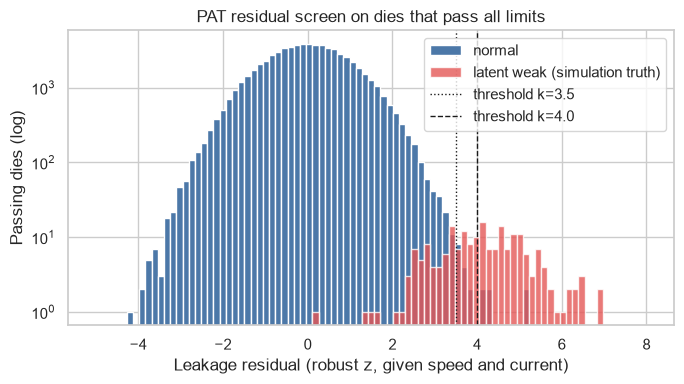

In [6]:
f = pat_frame.dropna(subset=["z_resid"])
fig, ax = plt.subplots(figsize=(7, 4))
bins = np.linspace(-5, max(f["z_resid"].max(), 8), 90)
if "is_weak" in f:
    ax.hist(f.loc[~f["is_weak"], "z_resid"], bins=bins, color="#4C78A8", label="normal", log=True)
    ax.hist(
        f.loc[f["is_weak"], "z_resid"],
        bins=bins,
        color="#E45756",
        alpha=0.8,
        label="latent weak (simulation truth)",
        log=True,
    )
else:
    ax.hist(f["z_resid"], bins=bins, color="#4C78A8", log=True)
for k, style in zip(PAT_K, [":", "--"], strict=True):
    ax.axvline(k, color="k", ls=style, lw=1, label=f"threshold k={k}")
ax.set_xlabel("Leakage residual (robust z, given speed and current)")
ax.set_ylabel("Passing dies (log)")
ax.set_title("PAT residual screen on dies that pass all limits")
ax.legend()
save(fig, "c06_pat_residual.png")

阈值 k 是**精度和召回的取舍**：k 从 3.5 提到 4.0，精度从约 90% 升到 95%，召回从约 70% 降到 54%。
实际定 k 要看这批芯片可接受的误杀成本，和一颗弱芯片流到客户端的代价。
图里红色和蓝色在 2.5–3.5 之间有重叠，这部分弱芯片靠"漏电残差"这一个维度是分不开的，召回上不去。

局限：模拟数据里弱芯片的"漏电偏大"信号是我设定的，残差法恰好对这个信号敏感；
真实产线的早夭缺陷未必都表现为漏电，要结合老化（burn-in）试验和客退数据来验证阈值。

## 4. 过杀与漏测（仅模拟数据）

- **过杀（overkill）**：本来合格的芯片被判失败（类比 AOI 的误报 FP），拉低良率、浪费产能；
- **漏测（escape）**：本来不合格的芯片被判通过（类比 AOI 的漏检 FN），流到客户端，用 DPPM 衡量。

首测和最终判定（复测之后）分别算。复测是一把双刃剑：它把一部分被冤枉的好芯片救回来（过杀下降），
但也会把一部分首测时被正确抓住的坏芯片复测放过（漏测上升）。

In [7]:
def overkill_escape(first_truth, by=None):
    f = first_truth.assign(scope="all") if by is None else first_truth
    key = by or "scope"
    rows = []
    for k, g in f.groupby(key):
        n_good, n_bad = int(g["intrinsic_pass"].sum()), int((~g["intrinsic_pass"]).sum())
        rows.append(
            {
                key: k,
                "intrinsic_good": n_good,
                "overkill_first": int((~g["tester_pass"] & g["intrinsic_pass"]).sum()),
                "overkill_final": int((~g["final_ok"] & g["intrinsic_pass"]).sum()),
                "intrinsic_bad": n_bad,
                "escape_first": int((g["tester_pass"] & ~g["intrinsic_pass"]).sum()),
                "escape_final": int((g["final_ok"] & ~g["intrinsic_pass"]).sum()),
            }
        )
    out = pd.DataFrame(rows)
    out["overkill_rate_first"] = out["overkill_first"] / out["intrinsic_good"]
    out["overkill_rate_final"] = out["overkill_final"] / out["intrinsic_good"]
    out["escape_rate_final"] = out["escape_final"] / out["intrinsic_bad"]
    return out


evaluation_result = None
if truth is not None:
    overall_oe = overkill_escape(first_t)
    by_lot_oe = overkill_escape(first_t, "lot_id")
    evaluation_result = {
        "overall": overall_oe.iloc[0].to_dict(),
        "by_lot": by_lot_oe.to_dict("records"),
    }
    display(overall_oe.T)
    display(by_lot_oe.round(4))

,0
scope,all
intrinsic_good,67429
overkill_first,984
overkill_final,568
intrinsic_bad,4478
escape_first,100
escape_final,157
overkill_rate_first,0.014593
overkill_rate_final,0.008424
escape_rate_final,0.03506


,lot_id,intrinsic_good,overkill_first,overkill_final,intrinsic_bad,escape_first,escape_final,overkill_rate_first,overkill_rate_final,escape_rate_final
0,L01,8506,18,3,486,16,25,0.0021,0.0004,0.0514
1,L02,8526,17,3,460,19,24,0.0020,0.0004,0.0522
2,L03,8449,18,3,537,13,18,0.0021,0.0004,0.0335
3,L04,8505,199,55,474,11,19,0.0234,0.0065,0.0401
4,L05,8486,240,195,503,9,13,0.0283,0.0230,0.0258
5,L06,8541,216,90,452,4,14,0.0253,0.0105,0.0310
6,L07,7957,35,16,1038,18,32,0.0044,0.0020,0.0308
7,L08,8459,241,203,528,10,12,0.0285,0.0240,0.0227


读法：

- **首测过杀集中在有测试硬件问题的 lot**（L04、L05、L06、L08 约 2%–3%，其余 lot 约 0.2%–0.4%），
  和上一个 Notebook 里归因出的线索对得上——这些"失败"里有相当一部分是测试系统冤枉的好芯片。
- **复测挽回的程度取决于问题类型**：接触和噪声这类间歇性问题（L04、L06）复测后过杀大幅下降；
  整台测试机偏移（L05、L08）复测几乎救不回来，最终过杀仍然在 2% 以上。
- **总体上，复测把过杀从约 1.5% 降到约 0.8%，同时漏测从 100 颗升到 157 颗**。
  漏测是最终流到客户端的，在真实产线上只能间接估计，所以"复测几次、复测策略"需要和质量团队一起定。

## 5. 测试效率：时间花在哪

这份数据是"继续测完"的工程验证模式（失败后不停），所以能算出每个测试项的**独有失败**——
只有它抓到、别的测试项都没抓到的芯片。量产时通常是"遇失败即停"，同一份数据可以反推**任何测试顺序**下的期望测试时间。

对每个测试项看四个量：耗时占比、失败数、独有失败数、与其他测试项的最大重叠（失败的芯片里，别的测试项也失败的比例）。

In [8]:
def fail_matrix(first, tests):
    return first[[f"fail_{n}" for n in tests["name"]]].to_numpy(dtype=bool)


def coverage_overlap(F):
    both = F.T.astype(int) @ F.astype(int)
    fails = np.diag(both).astype(float)
    with np.errstate(invalid="ignore", divide="ignore"):
        frac = both / fails[:, None]
    np.fill_diagonal(frac, 0.0)
    return pd.DataFrame(np.nan_to_num(frac))


def per_test_summary(first, tests):
    F = fail_matrix(first, tests)
    only_one = F.sum(axis=1) == 1
    names = list(tests["name"])
    overlap = coverage_overlap(F)
    overlap.index, overlap.columns = names, names
    table = pd.DataFrame(
        {
            "test": names,
            "time_ms": tests["time_ms"].to_numpy(),
            "time_share": tests["time_ms"].to_numpy() / tests["time_ms"].sum(),
            "fails": F.sum(axis=0),
            "unique_fails": (F & only_one[:, None]).sum(axis=0),
        }
    )
    table["unique_share"] = table["unique_fails"] / table["fails"].replace(0, np.nan)
    best = overlap.max(axis=1)
    table["max_covered_by_other"] = best.to_numpy()
    table["covered_by"] = overlap.idxmax(axis=1).where(best > 0).to_numpy()
    return table


eff = per_test_summary(first, tests)
eff.round(3)

,test,time_ms,time_share,fails,unique_fails,unique_share,max_covered_by_other,covered_by
0,CONT_VDD,20.0,0.009,189,177,0.937,0.021,SRAM_BIST
1,CONT_IO,20.0,0.009,0,0,NaN,0.000,NaN
2,IDD_STANDBY,60.0,0.026,1545,1414,0.915,0.056,IDD_ACTIVE
3,IDD_ACTIVE,80.0,0.034,95,0,0.000,0.905,IDD_STANDBY
4,VREF,50.0,0.021,526,0,0.000,1.000,LDO_OUT
5,LDO_OUT,50.0,0.021,529,1,0.002,0.994,VREF
6,OSC_FREQ,40.0,0.017,7,6,0.857,0.143,SRAM_BIST
7,PLL_LOCK,60.0,0.026,283,1,0.004,0.996,LDO_OUT
8,ADC_OFFSET,120.0,0.051,2,1,0.500,0.500,SCAN_FMAX
9,SCAN_FMAX,400.0,0.170,1160,1094,0.943,0.020,FUNC_PAT


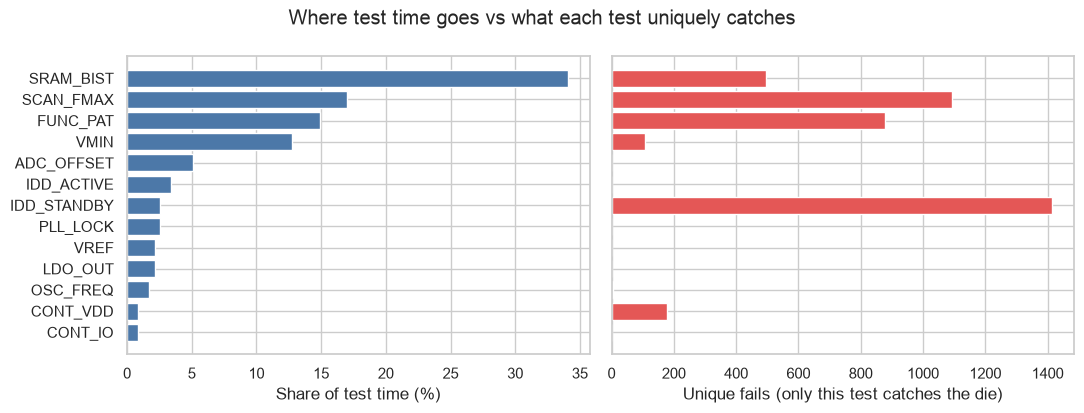

In [9]:
e = eff.sort_values("time_ms", ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
axes[0].barh(e["test"], e["time_share"] * 100, color="#4C78A8")
axes[0].set_xlabel("Share of test time (%)")
axes[0].invert_yaxis()
axes[1].barh(e["test"], e["unique_fails"], color="#E45756")
axes[1].set_xlabel("Unique fails (only this test catches the die)")
fig.suptitle("Where test time goes vs what each test uniquely catches")
save(fig, "c07_test_efficiency.png")

左图是时间花在哪，右图是每个测试项"独有"地抓到了多少芯片。
耗时最长的 `SRAM_BIST` 占了约三分之一的测试时间，但它约一半的失败是别的测试项抓不到的，
所以不能当冗余项删；要省它的时间，只能想办法缩短它本身（例如与 DFT 团队讨论更短的 BIST 算法、
或并行执行），而不是砍掉它。耗时短、独有失败几乎为零的测试项，才是下面冗余候选的来源。

### 冗余候选与"如果删掉"

失败几乎都被别的测试项同时抓到、自己几乎没有独有失败的测试项，是冗余的**候选**。
**数据里看起来冗余，不等于可以删**：必须回到故障模型和覆盖率（ATPG/BIST 覆盖了哪些缺陷）去确认。
这里输出的是给 DFT 与测试方案评审的候选清单，不是决定。

In [10]:
def redundancy_candidates(eff, min_covered=0.95, max_unique_share=0.05, min_fails=20):
    hit = eff[
        (eff["fails"] >= min_fails)
        & (eff["max_covered_by_other"] >= min_covered)
        & (eff["unique_share"].fillna(0) <= max_unique_share)
    ]
    return hit.sort_values("time_ms", ascending=False).reset_index(drop=True)


def expected_time(F, times, order):
    """遇失败即停：每颗芯片花到第一个失败项为止，全部通过则花完全部时间。返回平均每颗 ms。"""
    cum = np.cumsum(times[order])
    fo = F[:, order]
    stop = np.where(fo.any(axis=1), fo.argmax(axis=1), len(order) - 1)
    return float(cum[stop].mean())


def drop_candidates_saving(first, tests, drop):
    names = list(tests["name"])
    F = fail_matrix(first, tests)
    keep = [i for i, n in enumerate(names) if n not in drop]
    times = tests["time_ms"].to_numpy(dtype=float)
    before = expected_time(F, times, list(range(len(names))))
    after = expected_time(F, times, keep)
    escapes = int((F.any(axis=1) & ~F[:, keep].any(axis=1)).sum())
    return {"dropped": drop, "saving": 1 - after / before, "new_escapes": escapes, "dies": len(F)}


redundancy = redundancy_candidates(eff)
what_if = pd.DataFrame(
    [drop_candidates_saving(first, tests, [t]) | {"test": t} for t in redundancy["test"]]
)
display(redundancy.round(3))
display(what_if.round(4))

,test,time_ms,time_share,fails,unique_fails,unique_share,max_covered_by_other,covered_by
0,PLL_LOCK,60.0,0.026,283,1,0.004,0.996,LDO_OUT
1,VREF,50.0,0.021,526,0,0.000,1.000,LDO_OUT
2,LDO_OUT,50.0,0.021,529,1,0.002,0.994,VREF


,dropped,saving,new_escapes,dies,test
0,[PLL_LOCK],0.0258,1,71907,PLL_LOCK
1,[VREF],0.0215,0,71907,VREF
2,[LDO_OUT],0.0215,1,71907,LDO_OUT


`new_escapes` 是"如果删掉它，会多放过多少颗**只有它抓到**的失败芯片"。
候选清单里即使 `new_escapes` 很小，也要先确认这些失败对应的故障模型是否被别的测试项覆盖，
才能谈删除；省下的时间要和多放过的风险放在一起评审。

注意**这些候选不能一起删**：上表里 `VREF` 和 `LDO_OUT` 互相覆盖（各自的失败几乎都被对方同时抓到），
删掉其中一个没问题，两个都删就没有任何测试项能抓到这类失败了。逐个"如果删掉"的结果不能直接相加。
单个候选省的时间也只有 2% 左右。

### 测试顺序：改顺序能省多少

遇失败即停时，把"**单位耗时内最容易让芯片失败**"的测试项排在前面，能让多数失败芯片更早出局。
用贪心：每一步在"仍存活的芯片"里，选（条件失败率 / 耗时）最大的测试项；接触测试（`CONT_`）固定排在最前，
因为它也保护后面的测试不被接触不良的芯片误伤。

In [11]:
def greedy_order(F, times, pinned):
    order = list(pinned)
    alive = ~F[:, order].any(axis=1) if order else np.ones(len(F), dtype=bool)
    remaining = [j for j in range(F.shape[1]) if j not in order]
    while remaining:
        score = [F[alive, j].mean() / times[j] if alive.any() else 0.0 for j in remaining]
        pick = remaining[int(np.argmax(score))]
        order.append(pick)
        remaining.remove(pick)
        alive &= ~F[:, pick]
    return order


def order_optimization(first, tests, pinned_prefix="CONT_"):
    F = fail_matrix(first, tests)
    times = tests["time_ms"].to_numpy(dtype=float)
    names = list(tests["name"])
    pinned = [i for i, n in enumerate(names) if n.startswith(pinned_prefix)]
    current = expected_time(F, times, list(range(len(names))))
    best_order = greedy_order(F, times, pinned)
    best = expected_time(F, times, best_order)
    return {
        "full_time_ms": float(times.sum()),
        "current_ms": current,
        "optimized_ms": best,
        "saving": 1 - best / current,
        "optimized_order": [names[i] for i in best_order],
    }


order = order_optimization(first, tests)
print(f"全部测完 {order['full_time_ms']:.0f} ms/颗；遇失败即停：")
print(f"  当前顺序 平均 {order['current_ms']:.1f} ms/颗")
print(f"  贪心顺序 平均 {order['optimized_ms']:.1f} ms/颗，省 {order['saving']:.1%}")
print("  贪心顺序：", " -> ".join(order["optimized_order"]))

全部测完 2350 ms/颗；遇失败即停：
  当前顺序 平均 2250.3 ms/颗
  贪心顺序 平均 2216.8 ms/颗，省 1.5%
  贪心顺序： CONT_VDD -> CONT_IO -> IDD_STANDBY -> LDO_OUT -> FUNC_PAT -> SCAN_FMAX -> SRAM_BIST -> VMIN -> OSC_FREQ -> PLL_LOCK -> ADC_OFFSET -> IDD_ACTIVE -> VREF


改顺序只省约 1.5%。原因是大多数芯片都是合格的（首测良率超过九成），合格的芯片无论什么顺序都要把所有测试项
测完，顺序只影响少数失败芯片的出局时间。真正的杠杆在耗时最长的测试项本身，而不是调顺序。

## 6. 补全线索摘要

读取 Notebook 02 写出的前半部分，补上 PAT、测试顺序、仿真评估三部分。
重复运行本 Notebook 是安全的：这三个键会被覆盖，不会重复追加。

In [12]:
def clean(o):
    if isinstance(o, dict):
        return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [clean(v) for v in o]
    if isinstance(o, (np.floating, float)):
        return None if np.isnan(o) else round(float(o), 6)
    if isinstance(o, np.integer):
        return int(o)
    return o


summary = json.loads(SUMMARY.read_text())
summary["pat"] = clean(pat)
summary["order_optimization"] = clean({k: v for k, v in order.items() if k != "optimized_order"})
summary["evaluation"] = clean(evaluation_result)
SUMMARY.write_text(json.dumps(summary, ensure_ascii=False, indent=2))
print(f"saved -> {SUMMARY.relative_to(ROOT)}（{', '.join(summary)}）")

saved -> data/processed/chip_summary.json（overall, suspects, clusters, lot_process_shift, pat, order_optimization, evaluation）


## 局限性

- 数据是**模拟的**：弱芯片、缺陷、测试机行为都是按教学需要设定的。PAT 的精度/召回只说明方法在这份数据上
  行得通，不是对真实产线效果的估计。
- 真实产线**没有 `truth.csv`**：过杀只能靠复测推断，漏测只能靠可靠性试验、老化、客退和 DPPM 间接估计。
- 测试顺序优化假设各测试项的失败**相互独立于顺序**，且遇失败即停；真实测试程序里有依赖关系
  （例如先通电再测漏电），不是任何顺序都合法。
- 删除冗余测试项必须有故障模型和覆盖率证据，这里只给候选清单。